# 강화학습

위에서부터 순서대로 실행한다. `해답`이라고 적힌 칸은 문제를 먼저 생각한 뒤에 본다.

이 노트북의 흐름은 다음과 같다.

1. 강화학습이 지도학습과 다른 점, 보상, 탐험과 활용
2. 상태가 없는 선택: 슬롯머신
3. 상태, 마르코프 결정 과정, 할인 리턴, 벨만 기대 방정식
4. 길 찾기 예제로 방정식 계산과 몬테카를로 추정
5. 5×5 격자에서 랜덤 정책의 가치 계산
6. 정책을 더 좋게 고치는 정책 개선, 정책 반복, 가치 반복
7. 전이 확률 없이 배우는 몬테카를로, TD, SARSA, Q-러닝
8. 절벽 길에서 SARSA와 Q-러닝이 갈라지는 이유
9. 표로 값을 저장하기 어려운 화면 입력과 DQN

# **1. 지도학습과 강화학습**

### 지도학습

지도학습은 입력과 정답을 짝으로 준다. 사진과 "고양이"라는 라벨, 메일과 "스팸"이라는 라벨이 그런 짝이다. 모델은 예측과 정답의 차이인 손실을 줄이는 쪽으로 가중치를 고친다. 분류와 회귀가 여기에 들어간다.

### 강화학습

강화학습은 상태마다 정답 행동을 주지 않는다. 에이전트가 환경에서 행동을 고르면, 환경이 다음 상황과 보상을 돌려준다. 에이전트의 목표는 한 순간의 점수가 아니라, 앞으로 받을 보상을 할인해 더한 값을 키우는 정책을 찾는 것이다.

게임 AI, 로봇 제어, 바둑이 이런 문제에 가깝다. 지금 수가 맞았는지는 대국이 끝나야 알 수 있는 경우가 많다.

### 보상

보상은 환경이 행동 결과에 붙여 주는 숫자다.

- 양수는 그 결과가 좋았다는 신호이고, 음수는 나빴다는 신호인 경우가 많다.
- 매 걸음 들어올 수도 있고, 게임이 끝날 때 한 번만 들어올 수도 있다.
- 대부분의 순간에는 0이고 목표에 닿을 때만 점수가 생기면 희소 보상이다. 희소할수록 어떤 행동이 점수에 기여했는지 배우기 어렵다.
- 점수가 여러 걸음 뒤에 생기면 지연 보상이다. 초반의 어떤 행동이 마지막 점수에 기여했는지 나누어 보는 문제를 신용 할당 문제라고 한다.

강화학습의 목표는 눈앞의 보상만 키우는 것이 아니다. 할인율을 곱한 미래 보상까지 더한 누적 보상을 키운다.

### 에이전트

에이전트는 현재 상황을 보고 행동을 고른 뒤, 받은 보상으로 자신의 판단을 고치는 주체다.

1. 가치 기반 에이전트는 각 상태, 또는 상태와 행동의 가치를 숫자로 배운 다음 가치가 큰 행동을 고른다.
2. 정책 기반 에이전트는 상황별 행동 확률을 직접 고친다.
3. 액터-크리틱은 둘을 같이 둔다. 액터는 행동을 고르고, 크리틱은 그 행동이 얼마나 좋았는지 가치로 평가한다.

이 노트북은 가치 기반의 길을 따라간다. 정책의 가치를 계산하고, 그 가치로 행동을 고치고, 나중에는 경험만으로 행동 가치를 배운다.

### 몬테주마의 복수

![몬테주마의 복수](./images/몬테주마.png)

이 게임은 열쇠를 찾고, 문을 열고, 해골을 피해야 점수가 생긴다. 그 전까지 보상은 거의 0이다. 무작위로 조이스틱만 움직이면 한 번도 점수를 못 받고 게임이 끝난다. 보상이 드문 환경에서 스스로 탐험할 수 있는지가 여기서 드러난다. 노트북 끝에서 이 이야기로 다시 돌아온다.

### 탐험과 활용

탐험은 아직 몰라서, 또는 더 나은 수가 있을까 봐 새로운 행동을 해 보는 것이다. 활용은 지금까지의 경험으로 가장 좋아 보이는 행동을 반복하는 것이다.

활용만 하면 일찍 괜찮아 보인 행동에 머문다. 탐험만 하면 이미 좋은 행동을 알아도 점수를 쌓지 못한다. 강화학습은 이 둘의 비율을 정해야 한다. 뒤에서 만들 ε-greedy는 그중 한 가지 규칙이다. 확률 ε로는 아무 행동이나 고르고, 나머지 확률로는 현재 추정치가 가장 높은 행동을 고른다.

# **2. 강화학습을 게임에 대입**

| 용어 | 게임에서의 뜻 |
|---|---|
| 에이전트 | 조작하는 캐릭터 |
| 환경 | 벽, 몬스터, 점수 규칙을 가진 세계 |
| 상태 | 판단에 쓰는 현재 정보. 위치, 열쇠 보유 여부 |
| 관측 | 실제로 보이는 정보. 화면 일부일 수 있다 |
| 행동 | 위, 아래, 왼쪽, 오른쪽 |
| 보상 | 그 걸음에서 받은 점수 |
| 정책 | 상황마다 행동을 고르는 규칙 |
| 리턴 | 지금부터 받을 보상들을 할인해 더한 값 |
| 에피소드 | 시작부터 성공이나 실패까지 한 판 |

보상은 설계에 따라 학습 모습이 바뀐다.

- 즉시 보상: 동전을 줍는 순간 +1
- 지연 보상: 바둑은 여러 수 뒤에 승패로 +1 또는 -1
- 희소 보상: 미로 출구 전까지 0
- 설계의 함정: 앞으로 갈 때마다 +1을 주면, 출구로 가기보다 같은 구역을 왔다 갔다 하며 점수를 모을 수 있다

순차적 의사결정은 지금 손해처럼 보이는 우회로가 나중의 도착을 만드는 상황이다. 한 칸의 점수만 보면 그 우회로를 고르기 어렵다.

# **3. 슬롯머신**

상태가 바뀌지 않는 가장 작은 강화학습이다. 슬롯머신 5대 중 당첨 확률이 가장 높은 기계를 찾아야 한다.

- 실제 확률은 `[0.2, 0.5, 0.1, 0.8, 0.3]`이다. 4번 기계가 0.8로 가장 높다. 번호는 0부터 센다.
- 에이전트는 이 확률표를 보지 못한다. 기계를 당겨 보고 1 또는 0만 받는다.
- 1000번 당겨서 누적 보상을 키우는 것이 목표다.

세 가지 전략을 비교한다.

1. 랜덤: 다섯 대 중 하나를 균등하게 고른다.
2. 탐욕: 지금까지의 평균 보상이 가장 큰 기계만 당긴다.
3. ε-greedy: 확률 ε로는 아무 기계나, 나머지로는 현재 평균이 가장 큰 기계를 당긴다. ε는 0.1과 0.01을 쓴다.

평균은 과거 보상을 전부 다시 더하지 않는다. 기계를 `n`번 뽑았고 이전 평균이 `m`이며 새 보상이 `r`이면 새 평균은 `m + (r - m) / n`이다.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 학생에게 숨겨야 하는 실제 확률. 행동 선택 코드는 이 배열을 읽지 않는다.
TRUE_PROBS = np.array([0.2, 0.5, 0.1, 0.8, 0.3])
N_STEPS = 1000


def bandit_experiment(strategy="epsilon", epsilon=0.1, seed=2026):
    """슬롯머신을 N_STEPS번 당기고 누적 보상, 선택 횟수, 추정 확률을 돌려준다."""
    rng = np.random.default_rng(seed)
    counts = np.zeros(5, dtype=int)       # 기계별 선택 횟수
    estimates = np.zeros(5, dtype=float)  # 기계별 평균 보상 추정
    rewards = []

    for t in range(N_STEPS):
        # 처음 5번은 기계를 한 번씩 당겨 추정을 0에서 벗어나게 한다.
        if t < 5:
            action = t
        elif strategy == "random":
            action = int(rng.integers(5))
        elif strategy == "greedy":
            action = int(np.argmax(estimates))
        elif strategy == "epsilon":
            if rng.random() < epsilon:
                action = int(rng.integers(5))
            else:
                action = int(np.argmax(estimates))
        else:
            raise ValueError("unknown strategy")

        # 실제 확률과 난수를 비교해 당첨이면 1, 아니면 0. 이 줄만 정답을 사용한다.
        reward = float(rng.random() < TRUE_PROBS[action])
        counts[action] += 1
        estimates[action] += (reward - estimates[action]) / counts[action]
        rewards.append(reward)

    return np.cumsum(rewards), counts, estimates

In [ ]:
results = {
    "Random": bandit_experiment("random"),
    "Greedy": bandit_experiment("greedy"),
    "eps=0.1": bandit_experiment("epsilon", 0.1),
    "eps=0.01": bandit_experiment("epsilon", 0.01),
}

for name, (cumulative, counts, estimates) in results.items():
    best = int(np.argmax(counts))
    print(
        f"{name:8s} | 누적 보상={cumulative[-1]:.0f} | "
        f"선택 횟수={counts.tolist()} | 추정={estimates.round(2)} | 최다 선택={best}"
    )

plt.figure(figsize=(9, 4))
for name, (cumulative, _, _) in results.items():
    plt.plot(cumulative, label=name)
plt.xlabel("Number of actions")
plt.ylabel("Cumulative reward")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### 문제

1. 이번 시드(2026)에서 탐욕 전략은 4번 기계(확률 0.8)를 찾아내는가?
2. 탐욕 전략은 항상 그 기계를 찾는가?
3. ε가 0.1일 때와 0.01일 때, 선택 횟수는 어떻게 다른가?

In [ ]:
# 탐욕이 막히는 시드. 처음 다섯 번에서 1번 기계만 당첨된다.
bad_cum, bad_counts, bad_est = bandit_experiment("greedy", seed=2046)
print("seed 2046 탐욕 | 누적 보상=", bad_cum[-1], "| 선택 횟수=", bad_counts.tolist(), "| 추정=", bad_est.round(2))

#### 해답

1. 시드 2026에서는 찾아낸다. 처음 다섯 번을 한 대씩 당겨 본 뒤 4번 기계의 평균이 가장 높아서, 이후 거의 4번만 당긴다. 누적 보상은 780점대다. 랜덤은 기계를 고르게 당겨 370점대에 머문다.
2. 항상 찾지는 못한다. 시드 2046에서는 처음 다섯 번 중 1번 기계만 당첨이고 4번은 꽝이다. 탐욕은 그 한 번의 당첨을 끝까지 믿고 1번(실제 확률 0.5)만 당긴다. 4번을 다시 당겨 볼 기회가 없다.
3. ε=0.1은 열 번 중 한 번 정도 다른 기계를 눌러 추정은 안정적이지만, 이미 좋은 기계를 아는 뒤에도 탐험 비용이 든다. ε=0.01은 거의 활용이라 이번 시드에서는 누적 보상이 조금 더 높다. 초반에 최고 기계를 놓치면 0.01은 되돌릴 기회도 적다.

활용은 지금 추정치의 1등이다. 그 1등이 실제 1등이라는 보장은 없다.

# **4. 마르코프 결정 과정**

마르코프 성질은 한 문장으로 말할 수 있다. 현재 상태와 현재 행동을 알면, 다음 상태의 확률을 말하는 데 더 오래된 기록은 필요 없다. 현재 상태가 과거에 필요한 정보를 이미 요약하고 있다는 뜻이다.

### 마르코프 과정 (MP)

행동을 고르는 주체가 없다. 오늘이 맑으면 내일은 맑음 70%, 비 30%처럼 현재 상태만으로 다음 상태가 정해진다.

`MP = (S, P)`. S는 상태, P는 전이 확률이다.

### 마르코프 보상 과정 (MRP)

MP에 보상과 할인율을 더한다. 맑음에서 맑음으로 가면 +10, 비로 가면 -5처럼 전이에 점수가 붙는다.

`MRP = (S, P, R, γ)`

### 마르코프 결정 과정 (MDP)

에이전트가 행동을 고른다. 같은 상태에서도 위로 갈지 아래로 갈지에 따라 다음 상태 확률과 보상이 달라진다. 그래서 정책끼리 비교할 수 있다.

`MDP = (S, A, P, R, γ)`

예를 들어 위로 이동이 80%로 +10, 20%로 -10이면 기댓값은 `0.8*10 + 0.2*(-10) = 6`이다. 아래로 이동이 `0.6*5 + 0.4*(-5) = 1`이면, 한 걸음만 볼 때 위가 더 낫다. 강화학습은 이 비교를 여러 걸음의 미래까지 확장한다.

### 전이 확률

"오른쪽으로 가라"고 해도 다음 칸이 항상 오른쪽은 아닐 수 있다.

- 80%는 오른쪽
- 10%는 미끄러져 위
- 10%는 제자리

가능한 결과의 확률을 더하면 1이어야 한다. 아래 칸은 그 확률로 1만 번 뽑아 실험 비율이 설정값 근처에 모이는지 확인한다.

In [ ]:
transition = {"right": 0.8, "up": 0.1, "stay": 0.1}
assert np.isclose(sum(transition.values()), 1.0)

rng = np.random.default_rng(7)
samples = rng.choice(list(transition), size=10000, p=list(transition.values()))
for next_state in transition:
    ratio = np.mean(samples == next_state)
    print(next_state, "설정", transition[next_state], "실험 비율", round(float(ratio), 3))

### 정책, 상태 가치, 행동 가치

- 정책 π(a|s)는 상태 s에서 행동 a를 고를 확률이다. 한 행동만 고르는 정책도 있고, 네 방향을 25%씩 고르는 정책도 있다.
- 상태 가치 Vπ(s)는 s에서 시작해 이후에도 정책 π를 따를 때 기대되는 리턴이다.
- 행동 가치 Qπ(s, a)는 s에서 먼저 a를 하고, 그 다음부터 π를 따를 때 기대되는 리턴이다.

같은 격자라도 정책이 바뀌면 V와 Q가 바뀐다. 랜덤하게 걷는 정책의 V와, 집만 향해 걷는 정책의 V는 다른 표다.

### 할인율과 리턴

보상이 지금, 다음, 다다음에 10, 10, 10이라면

- γ=1이면 `10 + 10 + 10 = 30`
- γ=0.9이면 `10 + 9 + 8.1 = 27.1`
- γ=0.5이면 `10 + 5 + 2.5 = 17.5`

γ는 미래 보상을 현재 가치에 얼마나 남길지 정한다. 1에 가까우면 먼 보상도 꽤 남고, 0에 가까우면 눈앞의 보상만 남는다. 1에 가깝다는 말이 미래가 현재보다 중요하다는 뜻은 아니다. 지금 받는 10에는 γ가 곱해지지 않는다.

In [ ]:
rewards = [10, 10, 10]
for gamma in [0.0, 0.5, 0.9, 1.0]:
    discounted = sum((gamma ** t) * reward for t, reward in enumerate(rewards))
    print(f"gamma={gamma:.1f} -> return={discounted:.2f}")

# **5. 한 경로의 할인 리턴**

에이전트는 `working`에서 시작한다. 고를 수 있는 행동은 `working`, `gym`, `home`이다. `home`에 들어가면 그 경로는 끝이다.

| 현재 상태 | 행동 | 다음 상태 | 보상 |
|---|---|---|---|
| working | working | working | +3 |
| working | gym | gym | +5 |
| working | home | home | +12 |
| gym | working | working | +4 |
| gym | home | home | +12 |

리턴은 아래 식이다. 첫 보상의 지수를 0으로 둔다.

`G = R1 + γ R2 + γ^2 R3 + ...`

기본 할인율은 0.9다. 비교할 행동 순서는 두 가지다.

- A: working, working, home
- B: gym, working, home

리스트에 적힌 것은 상태 이름이 아니라 행동 이름이다. 시작 상태는 둘 다 working이다.

In [ ]:
TRANSITIONS = {
    ("working", "working"): ("working", 3),
    ("working", "gym"): ("gym", 5),
    ("working", "home"): ("home", 12),
    ("gym", "working"): ("working", 4),
    ("gym", "home"): ("home", 12),
}


def evaluate_actions(actions, gamma=0.9):
    """시작 상태 working에서 행동 리스트를 실행하고 (보상 리스트, 할인 리턴)을 돌려준다."""
    state = "working"
    rewards = []
    for action in actions:
        if state == "home":
            raise ValueError("종료 상태 뒤에 행동이 더 있다.")
        if (state, action) not in TRANSITIONS:
            raise ValueError(f"불가능한 행동: {state} -> {action}")
        state, reward = TRANSITIONS[(state, action)]
        rewards.append(reward)
    if state != "home":
        print("주의: 아직 home에 도착하지 않은 경로다.")
    total = sum((gamma ** t) * reward for t, reward in enumerate(rewards))
    return rewards, total


for name, actions in {
    "A": ["working", "working", "home"],
    "B": ["gym", "working", "home"],
}.items():
    path_rewards, total = evaluate_actions(actions)
    print(f"경로 {name}: 보상={path_rewards}, 할인 리턴={total:.2f}")

#### 해답

경로 A의 상태는 working → working → working → home이고 보상은 3, 3, 12다.

`3 + 0.9*3 + 0.81*12 = 15.42`

경로 B의 상태는 working → gym → working → home이고 보상은 5, 4, 12다.

`5 + 0.9*4 + 0.81*12 = 18.32`

둘 다 마지막에 같은 +12로 끝나지만, 그 전 두 번의 합이 B가 더 크다. 이 계산은 경로가 미리 주어졌을 때의 점수다. 다음 단원부터는 다음 장소가 확률로 갈라지고, 그 기댓값을 가치로 둔다.

# **6. 벨만 기대 방정식**

리턴은 앞으로 받을 보상을 할인해 더한 값이고, 가치는 그 리턴의 기댓값이다. 경로가 두세 걸음이면 보상을 직접 나열할 수 있다. 길이 수백 걸음으로 갈라지면 모든 미래를 적는 일이 어렵다.

벨만 기대 방정식은 그 나열을 다음 한 걸음으로 줄인다.

`지금 가치 = 지금 받을 보상 + γ × 다음 상태의 가치`

다음 예는 시작에서 중간으로 가며 +2, 중간에서 종료로 가며 +10을 받는다. γ=0.9이면 리턴은 `2 + 0.9*10 = 11`이다. 종료의 가치를 10으로 이미 알고 있다면 시작의 가치는 `2 + 0.9*10`으로 다시 쓸 수 있다. 미래 보상을 끝가지 펼치지 않고 다음 상태의 가치 하나를 빌려 온다.

다음 상태가 반반으로 갈라지면 그 가치도 평균한다. 좋은 칸의 가치가 10, 나쁜 칸의 가치가 -2이고 지금 보상이 0이면

`0 + 0.9 * (0.5*10 + 0.5*(-2)) = 3.6`

3.6은 실제로 주머니에 들어오는 점수가 아니다. 좋은 칸으로 가면 9점에 가깝고, 나쁜 칸으로 가면 -1.8에 가깝다. 3.6은 그 둘을 확률로 평균한 기대값이다.

정책까지 포함하면 상태 s의 가치는 이렇게 쓴다.

$$
V^\pi(s)=\sum_a \pi(a|s)\sum_{s'} P(s'|s,a)\big[R(s,a,s')+\gamma V^\pi(s')\big]
$$

읽는 순서는 안쪽에서 바깥이다.

1. 한 결과의 가치: `R + γ V(s')`
2. 한 행동의 가치: 그 행동이 만들 수 있는 다음 상태를 확률 P로 평균
3. 상태의 가치: 정책이 고르는 행동들을 확률 π로 평균

정책이 "네 방향을 각각 1/4"이면 3번은 네 행동 가치를 산술평균하는 것과 같다.

In [ ]:
good_value, bad_value = 10.0, -2.0
gamma = 0.9
expected_next = 0.5 * good_value + 0.5 * bad_value
print("다음 상태 가치의 평균:", expected_next)
print("지금 상태에서 기대하는 가치:", 0 + gamma * expected_next)

# **7. 집으로 돌아가는 길**

학생은 A, B, C 중 한 곳에 있다. 이동 확률은 이미 정해져 있고, 학생이 방향을 고르지는 못한다. 그래서 이 문제는 아직 MDP의 정책 비교가 아니라, 확률이 고정된 보상 과정의 상태 가치를 구하는 문제다.

| 현재 | 다음 | 확률 |
|---|---|---|
| A | Home | 70% |
| A | B | 30% |
| B | A | 50% |
| B | C | 50% |
| C | B | 50% |
| C | Bar | 50% |

Home과 Bar에 도착하면 이동이 끝난다. Home에 들어가는 순간 +1, Bar에 들어가는 순간 -1, 그 외 이동은 0이다. 할인율은 0.9다.

점수를 +10과 -10으로 바꿔도 부호와 순서는 같고 가치만 10배가 된다. 뒤의 5×5 격자와 숫자를 맞추려고 여기서부터 +1과 -1을 쓴다.

할 일은 다음과 같다.

- 상태, 이동 규칙, 종료 상태를 정의한다.
- 모든 가치를 0에서 시작한다.
- A, B, C에 벨만 기대 방정식을 반복 적용한다.
- 가치가 거의 변하지 않으면 멈춘다.

In [ ]:
CHAIN_GAMMA = 0.9
CHAIN_STATES = ["Home", "A", "B", "C", "Bar"]
CHAIN_NEXT = {
    "A": [("Home", 0.7), ("B", 0.3)],
    "B": [("A", 0.5), ("C", 0.5)],
    "C": [("B", 0.5), ("Bar", 0.5)],
}
CHAIN_TERMINAL = {"Home", "Bar"}


def arrival_reward(next_state):
    """다음 칸에 도착하는 순간 받는 보상. 집과 술집의 가치 자체가 아니라 들어가는 점수를 준다."""
    if next_state == "Home":
        return 1.0
    if next_state == "Bar":
        return -1.0
    return 0.0


def evaluate_chain(gamma=CHAIN_GAMMA, tol=1e-12, max_iter=1000):
    """고정된 이동 확률에 대해 A, B, C의 상태 가치를 반복 계산한다."""
    values = {state: 0.0 for state in CHAIN_STATES}
    for iteration in range(1, max_iter + 1):
        updated = values.copy()
        for state in ["A", "B", "C"]:
            total = 0.0
            for nxt, prob in CHAIN_NEXT[state]:
                # 종료 상태의 가치는 0으로 유지되므로, 집에 들어가는 보상이 곧 그 갈래의 전부가 된다.
                total += prob * (arrival_reward(nxt) + gamma * values[nxt])
            updated[state] = total
        delta = max(abs(updated[state] - values[state]) for state in CHAIN_STATES)
        values = updated
        if iteration in [1, 2, 5, 10, 20] or delta < tol:
            print(
                f"{iteration:3d}회 | A={values['A']:+.4f} | "
                f"B={values['B']:+.4f} | C={values['C']:+.4f} | 변화={delta:.2e}"
            )
        if delta < tol:
            return values, iteration
    raise RuntimeError("집으로 가는 길이 수렴하지 않았다.")


chain_values, chain_iters = evaluate_chain()
assert chain_iters < 100

In [ ]:
def evaluate_chain_quiet(gamma):
    values = {state: 0.0 for state in CHAIN_STATES}
    for _ in range(1000):
        updated = values.copy()
        for state in ["A", "B", "C"]:
            updated[state] = sum(
                prob * (arrival_reward(nxt) + gamma * values[nxt])
                for nxt, prob in CHAIN_NEXT[state]
            )
        delta = max(abs(updated[s] - values[s]) for s in CHAIN_STATES)
        values = updated
        if delta < 1e-12:
            return values
    raise RuntimeError("수렴하지 않았다.")


for gamma in [0.9, 1.0]:
    solved = evaluate_chain_quiet(gamma)
    print(
        f"gamma={gamma:.1f} | A={solved['A']:+.4f} | "
        f"B={solved['B']:+.4f} | C={solved['C']:+.4f}"
    )

### 문제

1. A, B, C 중 가치가 가장 높은 곳은 어디인가?
2. A가 B보다 높은 이유는 무엇인가?
3. C가 음수인 이유는 무엇인가?
4. 반복할수록 가치 변화량이 작아지는 이유는 무엇인가?
5. 할인율을 0.9에서 1로 바꾸면 무엇이 달라지는가?

#### 해답

γ=0.9에서 수렴값은 대략 A = +0.736, B = +0.133, C = -0.440이다. Home과 Bar는 시작부터 0이고, 반복에서도 그 칸은 갱신하지 않으므로 계속 0이다.

1. A가 가장 높다.
2. A는 70% 확률로 바로 집에 들어가 +1을 받는다. B는 집에서 한 단계 멀고, 절반은 C 쪽으로 내려간다.
3. C는 50% 확률로 바로 술집에 들어가 -1을 받는다. 나머지 50%도 B를 거쳐 돌아가야 하므로 집의 +1이 많이 할인된다.
4. 새 가치는 이전 가치들의 가중평균이다. 값이 방정식에 가까워지면 대입 결과가 입력과 거의 같아져서 변화량이 줄어든다. 이 반복이 정책 평가의 기본 형태다.
5. γ=1이면 A = 0.750, B = 0.167, C = -0.417이다. A와 B는 미래가 전부 남아 조금 커진다. C는 오히려 음수의 절댓값이 줄어든다. C에게 나쁜 -1은 바로 다음 걸음이라 할인이 거의 없고, 좋은 +1은 여러 걸음 뒤라 γ가 낮으면 더 많이 깎이기 때문이다.

# **8. 몬테카를로 방법**

몬테카를로는 기댓값을 식으로 평균하는 대신, 끝난 판을 많이 모아 그 리턴의 평균으로 추정한다.

$$
V(s) \approx \frac{1}{N(s)}\sum_{i=1}^{N(s)} G_i(s)
$$

$$
G = R_1 + \gamma R_2 + \gamma^2 R_3 + \cdots
$$

A에서 다섯 판만 돌리면 이런 결과가 나올 수 있다. 이 표의 점수는 설명을 위한 도착 보상이다.

| 판 | 도착 | 도착 보상 |
|---|---|---|
| 1 | Home | +1 |
| 2 | Home | +1 |
| 3 | Bar | -1 |
| 4 | Home | +1 |
| 5 | Home | +1 |

평균은 0.6이다. 판이 5개뿐이라 앞 단원의 A 가치 0.736과 다르다. 판을 늘리면 평균은 그 가치 쪽으로 움직인다.

| | 벨만 반복 | 몬테카를로 |
|---|---|---|
| 계산 | 전이 확률로 기댓값을 갱신 | 끝난 판의 리턴을 평균 |
| 전이 확률 | 있어야 한다 | 없어도 된다 |
| 에피소드 | 돌릴 필요가 없다 | 종료까지 돌려야 한다 |
| 결과 | 같은 입력에 같은 수렴값 | 표본이 바뀌면 추정치가 조금 움직인다 |
| 이름 | 모델 기반 | 모델 프리 |

모델은 여기서 `(다음 상태, 확률, 보상)`을 아는 것을 말한다.

In [ ]:
def chain_episode_return(start, rng, gamma=CHAIN_GAMMA):
    """start에서 집이나 술집에 도착할 때까지 걷고, 그 판의 할인 리턴을 돌려준다."""
    state = start
    rewards = []
    while state not in CHAIN_TERMINAL:
        options, probs = zip(*CHAIN_NEXT[state])
        nxt = str(rng.choice(list(options), p=list(probs)))
        rewards.append(arrival_reward(nxt))
        state = nxt
    total = 0.0
    for reward in reversed(rewards):
        total = reward + gamma * total
    return total


rng = np.random.default_rng(2026)
for start in ["A", "B", "C"]:
    scores = [chain_episode_return(start, rng) for _ in range(10000)]
    print(
        f"{start}: 몬테카를로={np.mean(scores):+.4f} | "
        f"벨만={chain_values[start]:+.4f} | 판 수=10000"
    )

#### 해답

A와 C의 몬테카를로 평균은 벨만 값과 소수 셋째 자리 근처에서 만난다. B는 집과 술집까지 가는 길이가 들쭉날쭉해서 평균의 흔들림이 조금 더 크다. 판 수를 더 늘리면 B도 벨만 값에 더 붙는다.

이 차이는 방법의 차이다. 벨만 반복은 전이 확률 0.7, 0.3을 식에 넣어 한 값으로 수렴한다. 몬테카를로는 그 확률을 모르고, 실제로 걸은 결과만 평균한다.

# **9. 5×5 격자에서 랜덤 정책 평가**

이제 학생이 방향을 고를 수 있다. 세계는 5×5 격자다.

- 상태는 `(행, 열)`이다. 행 0이 위, 열 0이 왼쪽이다.
- Home은 `(0, 0)`, Bar는 `(0, 4)`다.
- 행동은 up, down, left, right이고 한 칸 이동한다. up은 행을 1 줄인다.
- 격자 밖으로 나가는 행동은 그 자리에 남는다.
- Home에 들어가는 순간 +1, Bar에 들어가는 순간 -1, 다른 이동은 0이다.
- Home이나 Bar에 들어간 뒤에는 행동이 없고 추가 보상도 없다. 두 칸의 가치는 0이다.
- 할인율은 0.95다. 1보다 작아야, 같은 칸을 영원히 빙빙 도는 정책도 유한한 가치를 갖는다.

이번 단원의 정책은 랜덤이다. 집과 술집이 아닌 모든 칸에서 네 행동을 각각 확률 1/4로 고른다.

이 코드는 에이전트를 어떤 한 칸에 세워 두고 출발시키지 않는다. 25칸 모두에 대해 "지금 이 칸에 있다면 이후 랜덤하게 걸을 때의 가치"를 동시에 계산한다. Home은 출발점이 아니라 끝나는 칸이다.

### 문제

1. 상태 집합, 행동 집합, 종료 상태, 보상 규칙을 각각 한 문장으로 정리한다.
2. 다음 전이의 다음 상태, 보상, 종료 여부를 구한다.
   - `(1, 0)`에서 up
   - `(0, 1)`에서 left
   - `(0, 3)`에서 right
   - `(2, 0)`에서 left
   - `(0, 0)`에서 down
3. 한 칸을 갱신하는 식이 왜 네 행동의 평균인지 설명한다. 종료 상태로 들어갈 때 다음 가치를 0으로 두는 이유도 포함한다.
4. Home과 Bar의 가치가 처음부터 끝까지 0인 이유를 코드의 두 지점과 연결해 설명한다.
5. γ=0.95로 실행한 표에서, 왼쪽이 양수이고 오른쪽이 음수이며 가운데 열이 0인 이유를 설명한다.
6. γ를 0.5로 낮추면 부호는 유지되는가? 절댓값은 어떻게 달라지는가?

In [26]:
SIZE = 5
HOME = (0, 0)
BAR = (0, 4)
GAMMA = 0.95
ACTIONS = {
    "up": (-1, 0),
    "down": (1, 0),
    "left": (0, -1),
    "right": (0, 1)
}
ACTION_NAMES = ['up', 'down', 'left', 'right']
ARROWS = {"up": "↑", "down": "↓", "left": "←", "right": "→", None: "·"}

In [27]:
def grid_step(state, action):
    if state in (HOME, BAR):
        return state, 0.0, True
    dr, dc = ACTIONS[action]
    row, col = state
    next_state = (min(max(row+dr, 0), SIZE-1), min(max(col+dc, 0), SIZE-1))
    if next_state == HOME:
        reward = 1.0
    elif next_state == BAR:
        reward = -1.0
    else:
        reward = 0.0
    done = next_state in (HOME, BAR)
    return next_state, reward, done

In [28]:
def show_values(values, digits=3):
    print(np.array2string(np.round(values, digits), formatter={"float_kind": lambda x: f"{x:7.{digits}f}"}))

In [44]:
def show_policy(policy):
    for row in range(SIZE):
        print(" ".join(ARROWS[policy[row, col]] for col in range(SIZE)))

In [45]:
samples = [
    ((1, 0), "up"),
    ((0, 1), "left"),
    ((0, 3), "right"),
    ((2, 0), "left"),
    ((0, 0), "down")
]

for state, action in samples:
    nxt, reward, done = grid_step(state, action)
    print(f"{state} + {action:5s} -> {nxt}, 보상={reward:+.0f}, 종료={done}")

(1, 0) + up    -> (0, 0), 보상=+1, 종료=True
(0, 1) + left  -> (0, 0), 보상=+1, 종료=True
(0, 3) + right -> (0, 4), 보상=-1, 종료=True
(2, 0) + left  -> (2, 0), 보상=+0, 종료=False
(0, 0) + down  -> (0, 0), 보상=+0, 종료=True


In [46]:
def evaluate_random_policy(gamma=GAMMA, tol=1e-10, max_iter=10000):
    values = np.zeros((SIZE, SIZE))
    for iteration in range(max_iter):
        updated = values.copy()
        for row in range(SIZE):
            for col in range(SIZE):
                state = (row, col)
                if state in (HOME, BAR):
                    continue
                action_values = []
                for action in ACTION_NAMES:
                    nxt, reward, done = grid_step(state, action)
                    future = 0.0 if done else values[nxt]
                    action_values.append(reward + gamma * future)
                updated[state] = np.mean(action_values)
        delta = np.max(np.abs(updated - values))
        values = updated
        if delta < tol:
            return values, iteration + 1
    raise RuntimeError("랜덤 정책 평가가 수렴하지 않음")

In [47]:
random_values, random_iters = evaluate_random_policy()
print("gamma=0.95 반복 횟수: ", random_iters)
show_values(random_values)
assert random_values[HOME] == 0 and random_values[BAR] == 0

low_values, low_iters = evaluate_random_policy(gamma=0.5)
print("gamma=0.5 반복 횟수: ", low_iters)
show_values(low_values)

gamma=0.95 반복 횟수:  109
[[  0.000   0.401   0.000  -0.401   0.000]
 [  0.470   0.236   0.000  -0.236  -0.470]
 [  0.219   0.124   0.000  -0.124  -0.219]
 [  0.110   0.065   0.000  -0.065  -0.110]
 [  0.069   0.042  -0.000  -0.042  -0.069]]
gamma=0.5 반복 횟수:  25
[[  0.000   0.297   0.000  -0.297   0.000]
 [  0.303   0.077   0.000  -0.077  -0.303]
 [  0.047   0.016   0.000  -0.016  -0.047]
 [  0.007   0.003   0.000  -0.003  -0.007]
 [  0.001   0.001   0.000  -0.001  -0.001]]


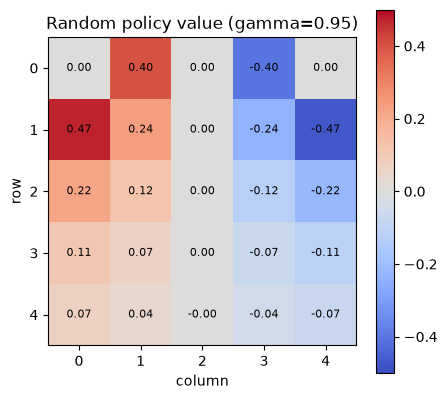

In [48]:
def heatmap(values, title, vmin, vmax):
    plt.figure(figsize=(4.6, 4.2))
    plt.imshow(values, cmap="coolwarm", vmin=vmin, vmax=vmax, origin="upper")
    plt.colorbar()
    plt.title(title)
    plt.xlabel("column")
    plt.ylabel("row")
    plt.xticks(range(SIZE))
    plt.yticks(range(SIZE))
    for row in range(SIZE):
        for col in range(SIZE):
            plt.text(col, row, f"{values[row, col]:.2f}", ha="center", va="center", fontsize=8)
    plt.tight_layout()
    plt.show()


heatmap(random_values, "Random policy value (gamma=0.95)", -0.5, 0.5)

# **10. 정책 개선**
- 랜덤 정책의 가치는 "마구 걸으면 이 칸이 얼마나 좋은가?"임
- 그 숫자를 이용하면 각 칸에서 더 나은 화살표를 고를 수 있음
- Q(s, a) = r + γ * (종료면 0, 아니면 V(s'))
- 개선된 정책은 각 칸에서 이 Q가 가장 큰 행동을 고름. 점수가 같으면 up, down, left, right 중 먼저 나온 행동을 고름

In [49]:
def action_scores(state, values, gamma=GAMMA):
    scores = []
    for action in ACTION_NAMES:
        nxt, reward, done = grid_step(state, action)
        future = 0.0 if done else values[nxt]
        scores.append(reward + gamma * future)
    return scores

In [50]:
def greedy_policy_from(values, gamma=GAMMA):
    policy = np.empty((SIZE, SIZE), dtype=object)
    for row in range(SIZE):
        for col in range(SIZE):
            state = (row, col)
            if state in (HOME, BAR):
                policy[state] = None
            else:
                policy[state] = ACTION_NAMES[int(np.argmax(action_scores(state, values, gamma)))]
    return policy

In [51]:
one_step_policy = greedy_policy_from(random_values)
print("랜덤 정책 가치로 한 번만 개선한 화살표")
show_policy(one_step_policy)

랜덤 정책 가치로 한 번만 개선한 화살표
· ← ← ← ·
↑ ← ← ← ↓
↑ ↑ ← ← ↓
↑ ↑ ← ← ←
↑ ← ← ← ←


In [52]:
for action, score in zip(ACTION_NAMES, action_scores((1, 4), random_values)):
    print(f"   {action:5s} {score:_.3f}")

   up    -1.000
   down  -0.208
   left  -0.224
   right -0.446


# **11. 정책 반복**
정책 반복은 두 단계를 정책이 변하지 않을 때까지 반복
1. 정책 평가: 지금 화살표를 고정하고, 그 화살표만 따르는 V가 수렴할 때까지 갱신
2. 쟁책 개선: 그 V로 각 칸의 화살표를 다시 그림

> 평가 > 개선 > 비교 > 다시 평가(반복)

In [53]:
def evaluate_policy(policy, gamma=GAMMA, tol=1e-10, max_iter=10000):
    values = np.zeros((SIZE, SIZE))
    for iteration in range(max_iter):
        updated = values.copy()
        for row in range(SIZE):
            for col in range(SIZE):
                state = (row, col)
                if state in (HOME, BAR):
                    continue
                nxt, reward, done = grid_step(state, policy[state])
                future = 0.0 if done else values[nxt]
                updated[state] = reward + gamma * future
        delta = np.max(np.abs(updated - values))
        values = updated
        if delta < tol:
            return values, iteration + 1
    raise RuntimeError("정책 평가가 수렴되지 않았음")

In [54]:
def policies_equal(left, right):
    return all(left[r, c] == right[r, c] for r in range(SIZE) for c in range(SIZE))

In [55]:
def policy_iteration(gamma=GAMMA, max_outer=20):
    policy = np.full((SIZE, SIZE), 'right', dtype=object)
    policy[HOME] = None
    policy[BAR] = None
    for outer in range(1, max_outer + 1):
        values, eval_iters = evaluate_policy(policy, gamma=gamma)
        imporved = greedy_policy_from(values, gamma=gamma)
        print(f"바깥 {outer}회 | 평가 반복={eval_iters}")
        show_policy(imporved)
        if policies_equal(policy, imporved):
            return values, imporved, outer
        policy = imporved
    raise RuntimeError("정책 반복이 끝나지 않음")

In [ ]:
pi_values, pi_policy, pi_rounds = policy_iteration()
print("정책 반복 최종 가치")
show_policy(pi_values)

print("정책 반복 최종 가치")
show_values(pi_values)

print("정책 반복 최종 정책")
show_policy(pi_policy)

# 반복 횟수 출력
print("정책 반복 횟수:", pi_rounds)

바깥 1회 | 평가 반복=4
· ← ↓ ↓ ·
↑ ↓ ↓ ↓ ↓
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
바깥 2회 | 평가 반복=5
· ← ← ↑ ·
↑ ↑ ↑ ↑ ↓
↑ ← ↑ ↑ ↑
↑ ← ↑ ↑ ↑
↑ ← ↑ ↑ ↑
바깥 3회 | 평가 반복=7
· ← ← ← ·
↑ ↑ ↑ ← ↓
↑ ↑ ↑ ← ↑
↑ ↑ ↑ ← ↑
↑ ↑ ↑ ← ↑
바깥 4회 | 평가 반복=8
· ← ← ← ·
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ←
바깥 5회 | 평가 반복=9
· ← ← ← ·
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
바깥 6회 | 평가 반복=9
· ← ← ← ·
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
바깥 1회 | 평가 반복=4
· ← ↓ ↓ ·
↑ ↓ ↓ ↓ ↓
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
바깥 2회 | 평가 반복=5
· ← ← ↑ ·
↑ ↑ ↑ ↑ ↓
↑ ← ↑ ↑ ↑
↑ ← ↑ ↑ ↑
↑ ← ↑ ↑ ↑
바깥 3회 | 평가 반복=7
· ← ← ← ·
↑ ↑ ↑ ← ↓
↑ ↑ ↑ ← ↑
↑ ↑ ↑ ← ↑
↑ ↑ ↑ ← ↑
바깥 4회 | 평가 반복=8
· ← ← ← ·
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ←
바깥 5회 | 평가 반복=9
· ← ← ← ·
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
바깥 6회 | 평가 반복=9
· ← ← ← ·
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
정책 반복 최종 가치
[[  0.000   1.000   0.950   0.902   0.000]
 [  1.000   0.950   0.902   0.857   0.815]
 [  0.950   0.902   0.857   0.815   0.774]
 [  0.902   0.857   0.815   0.774   0.735]
 [  0.857   0.815   0.77